# v1 – Predict the time constant τ, then compute t90

The second model version. It keeps everything of [v0](v0_base.ipynb) (data, split, inputs, models) and changes only the target.

![Flow of v1_tau](images/v1_tau_flow.png)

**How to read it:** grey is the data, blue the training on the training cases, orange the prediction and the scores on the test cases. The two vertical arrows are what training hands over to the prediction: the fitted scaling and categories, and the fitted models. Steps with a thick border and a tag are new in this version.

| | v0 | v1 |
|---|---|---|
| Model target | `t90_s` | log(`tau_s`) |
| Training cases | 372, only those with t90 | all 432 |
| t90 | predicted directly | computed: t90 = ln(10) · τ ≈ 2.30 · τ |
| Models | mean value, LinearRegression, Ridge, DecisionTree | the same, with the same parameters |

Why: v0 had to leave out every case that does not reach 90 % within 600 s, among them almost all same-wall cases, and its linear models predicted negative times. τ is defined for every case and can be kept positive.

The column meanings are in [results/README.md](../results/README.md).

## 1) Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

VERSION = "v1_tau"
RANDOM_STATE = 42
LN10 = np.log(10)  # t90 = ln(10) * tau, see section 3

DATA_PATH = Path("../results/dataset_550/dataset_550.csv")
RESULTS_DIR = Path("results")
print("Data file:", DATA_PATH, "| found:", DATA_PATH.exists())

Data file: ../results/dataset_550/dataset_550.csv | found: True


## 2) Load the data

Only rows with `status = ok` are used. The 9 `failed` rows have no results (a numerical fault in the simulation; they will be rerun).

`case_id` becomes the index, so every prediction can be traced back to its simulation.

In [2]:
df = pd.read_csv(DATA_PATH)
df = df[df["status"] == "ok"].set_index("case_id")

TARGET_COL = "t90_s"
# Only values that are fixed before a simulation starts (same choice as in unit 2)
FEATURE_COLS = [
    "layout",
    "window1_x_m",
    "window1_mode",
    "window1_angle_deg",
    "window1_hinge",
    "window2_x_m",
    "window2_mode",
    "window2_angle_deg",
    "window2_hinge",
    "wind_speed_ms",
]

print("Simulations:", len(df))
print("Missing input values:", int(df[FEATURE_COLS].isna().sum().sum()))

t90_reached = df[TARGET_COL].notna()
display(pd.crosstab(
    df["layout"],
    t90_reached.map({True: "t90 reached", False: "t90 > 600 s"}),
    margins=True,
    margins_name="total",
))

Simulations: 541
Missing input values: 0


t90_s,t90 > 600 s,t90 reached,total
layout,,,
adjacent_walls,22,228,250
opposite_walls,20,230,250
same_wall,34,7,41
total,76,465,541


Most same-wall cases (both windows in the wind-facing wall) do not reach 90 % within the 10 simulated minutes, so they have no `t90_s`.

## 3) Train/test split – the same in every version

- 80 % of the simulations for training, 20 % for testing, `random_state = 42`.
- Stratified by layout **and** by whether t90 is reached. Same-wall cases are rare (41) and mostly do not reach t90; without this, the test set got only 5 of them.
- The split is made on all `ok` cases, before anything is left out. **Every later version uses exactly this code**, so all versions are tested on the same simulations. Changing it makes the versions incomparable.
- The separate test run `test-v1` (30 new simulations) will be the final test once it has run. Until then, this split is used to compare the versions.

In [3]:
strata = df["layout"] + " / " + np.where(t90_reached, "reached", "not reached")

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=strata,
)

print("Training simulations:", len(train_df))
print("Test simulations:    ", len(test_df))
display(pd.crosstab(test_df["layout"], test_df[TARGET_COL].notna().map({True: "t90 reached", False: "t90 > 600 s"})))

Training simulations: 432
Test simulations:     109


t90_s,t90 > 600 s,t90 reached
layout,,
adjacent_walls,5,46
opposite_walls,4,46
same_wall,7,1


### Only in v1: the target is log(τ), for every case

`tau_s` (τ) is the time constant of the air-replacement curve, fresh_fraction ≈ 1 − exp(−t / τ). It is defined for every simulation, also when 90 % are not reached within 600 s. v1 therefore trains on all training cases, including the 33 same-wall cases (v0: 6).

The model learns **log(τ)** instead of τ:

- τ = exp(prediction) is always positive, so there are no negative times.
- τ scales roughly with 1 / wind speed. In log space such factors become sums, which suits a linear model.
- An error of a factor of 2 counts the same for a fast and for a slow case.

t90 follows from the curve shape: 1 − exp(−t90 / τ) = 0.9 gives **t90 = ln(10) · τ ≈ 2.30 · τ**.

In [4]:
TAU_COL = "tau_s"

X_train, y_train = train_df[FEATURE_COLS], np.log(train_df[TAU_COL])
X_test = test_df[FEATURE_COLS]

print("Training:", X_train.shape, "| Test:", X_test.shape)
display(pd.DataFrame({
    "train": train_df["layout"].value_counts(),
    "test": test_df["layout"].value_counts(),
}))

Training: (432, 10) | Test: (109, 10)


,train,test
layout,,
adjacent_walls,199,51
opposite_walls,200,50
same_wall,33,8


**How exact is t90 = ln(10) · τ?** The simulated curves are not exactly exponential. The check uses the training cases that have both values:

In [5]:
both = train_df[train_df[TARGET_COL].notna()]
ratio = both[TARGET_COL] / both[TAU_COL]
conversion_error = mean_absolute_error(both[TARGET_COL], LN10 * both[TAU_COL])

print(f"t90 / τ: mean {ratio.mean():.3f}, from {ratio.min():.2f} to {ratio.max():.2f} (ln 10 = {LN10:.3f})")
print(f"t90 from the simulated τ: MAE {conversion_error:.1f} s")

t90 / τ: mean 2.334, from 2.03 to 2.65 (ln 10 = 2.303)
t90 from the simulated τ: MAE 5.0 s


Even a perfect τ model would miss t90 by only a few seconds on average. Larger errors come from predicting τ, not from the conversion.

## 4) Preprocessing

As in units 2 and 3: numeric inputs are standardised, categorical inputs are one-hot encoded. There is no imputer, because the inputs have no missing values (checked in section 2).

`build_preprocessor()` returns a new, unfitted preprocessor on every call, so each model pipeline is fitted on its own.

In [6]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [col for col in FEATURE_COLS if col not in num_cols]


def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), num_cols),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


print("Numeric inputs:    ", num_cols)
print("Categorical inputs:", cat_cols)

Numeric inputs:     ['window1_x_m', 'window1_angle_deg', 'window2_x_m', 'window2_angle_deg', 'wind_speed_ms']
Categorical inputs: ['layout', 'window1_mode', 'window1_hinge', 'window2_mode', 'window2_hinge']


## 5) Models as pipelines

The same pipelines and parameters as in v0. Only the target differs: the models are fitted on log(τ), and `np.exp` turns their predictions back into τ in seconds.

In [7]:
models = {
    "Mean value (reference)": DummyRegressor(strategy="mean"),
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "DecisionTree": DecisionTreeRegressor(max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE),
}

pipelines = {}
tau_pred = pd.DataFrame(index=X_test.index)
for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocess", build_preprocessor()),
        ("model", model),
    ])
    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline
    tau_pred[name] = np.exp(pipeline.predict(X_test))  # log(τ) -> τ in seconds

t90_pred = LN10 * tau_pred

display(pd.concat([test_df[[TAU_COL, TARGET_COL]], tau_pred.add_prefix("τ ")], axis=1).head().round(0))

,tau_s,t90_s,τ Mean value (reference),τ LinearRegression,τ Ridge,τ DecisionTree
case_id,,,,,,
train-a-v2_092,77.0,187.0,99.0,83.0,85.0,78.0
train-a-v2_136,75.0,173.0,99.0,54.0,57.0,103.0
train-v1_074,28.0,64.0,99.0,29.0,30.0,29.0
train-v1_095,199.0,458.0,99.0,181.0,182.0,208.0
train-v1_080,23.0,50.0,99.0,44.0,45.0,45.0


## 6) Evaluation on the test cases

### 6.1 t90, compared with v0

The same scores as in v0 (MAE, RMSE, R²; see v0 section 6) on the same 93 test cases: those of the shared split that have a t90 value.

In [8]:
def scores(y_true, y_pred):
    return {
        "MAE [s]": mean_absolute_error(y_true, y_pred),
        "RMSE [s]": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred),
        "lowest prediction [s]": np.min(y_pred),
    }


has_t90 = test_df[TARGET_COL].notna()
y_test_t90 = test_df.loc[has_t90, TARGET_COL]
results = pd.DataFrame({name: scores(y_test_t90, t90_pred.loc[has_t90, name]) for name in t90_pred}).T
display(results.round(3))

v0_scores = pd.read_csv(RESULTS_DIR / "v0_base.csv").set_index("model")
display(pd.DataFrame({
    "v0 MAE [s]": v0_scores["MAE [s]"],
    "v1 MAE [s]": results["MAE [s]"],
    "v0 RMSE [s]": v0_scores["RMSE [s]"],
    "v1 RMSE [s]": results["RMSE [s]"],
    "v0 R²": v0_scores["R²"],
    "v1 R²": results["R²"],
}).round(3))

,MAE [s],RMSE [s],R²,lowest prediction [s]
Mean value (reference),115.568,142.251,-0.007,228.013
LinearRegression,50.206,75.951,0.713,47.661
Ridge,50.135,77.116,0.704,49.489
DecisionTree,57.922,85.315,0.638,65.723


,v0 MAE [s],v1 MAE [s],v0 RMSE [s],v1 RMSE [s],v0 R²,v1 R²
Mean value (reference),114.969,115.568,142.066,142.251,-0.005,-0.007
LinearRegression,53.050,50.206,70.382,75.951,0.753,0.713
Ridge,53.450,50.135,73.060,77.116,0.734,0.704
DecisionTree,42.081,57.922,62.447,85.315,0.806,0.638


### 6.2 Where the error changed

The mean absolute t90 error of v0 and v1, split by the simulated t90. `v0_base_test_predictions.csv` holds v0's predictions for the same test cases.

In [9]:
v0_pred = pd.read_csv(RESULTS_DIR / "v0_base_test_predictions.csv", index_col="case_id")
t90_range = pd.cut(y_test_t90, bins=[0, 100, 200, 300, 400, 600],
                   labels=["≤ 100 s", "100–200 s", "200–300 s", "300–400 s", "400–600 s"])

by_range = {"n": y_test_t90.groupby(t90_range, observed=True).size()}
for name in ["LinearRegression", "Ridge", "DecisionTree"]:
    for version, pred in [("v0", v0_pred.loc[y_test_t90.index, name]), ("v1", t90_pred.loc[has_t90, name])]:
        by_range[f"{version} {name}"] = (pred - y_test_t90).abs().groupby(t90_range, observed=True).mean()
display(pd.DataFrame(by_range).T.round(0).rename_axis("MAE [s] by simulated t90"))

t90_s,≤ 100 s,100–200 s,200–300 s,300–400 s,400–600 s
MAE [s] by simulated t90,,,,,
n,24.0,26.0,24.0,5.0,14.0
v0 LinearRegression,56.0,35.0,26.0,68.0,122.0
v1 LinearRegression,25.0,20.0,42.0,120.0,140.0
v0 Ridge,53.0,34.0,25.0,91.0,125.0
v1 Ridge,26.0,18.0,40.0,133.0,140.0
v0 DecisionTree,28.0,27.0,44.0,88.0,75.0
v1 DecisionTree,40.0,43.0,52.0,94.0,114.0


### 6.3 τ on all test cases

v1 can also be scored on the 16 test cases without t90. The *median relative error* is the typical deviation in percent of τ: 0.20 means 20 %. *R² of log(τ)* is the R² of what the models were fitted on.

In [10]:
tau_test = test_df[TAU_COL]
relative_error = tau_pred.sub(tau_test, axis=0).abs().div(tau_test, axis=0)

tau_scores = pd.DataFrame({
    name: {
        "MAE τ [s]": mean_absolute_error(tau_test, tau_pred[name]),
        "median relative error": relative_error[name].median(),
        "R² of log(τ)": r2_score(np.log(tau_test), np.log(tau_pred[name])),
    }
    for name in tau_pred
}).T
display(tau_scores.round(3))

per_layout = relative_error.groupby(test_df["layout"]).median()
per_layout.insert(0, "n", test_df["layout"].value_counts())
display(per_layout.round(2).rename_axis("median relative error of τ by layout"))

,MAE τ [s],median relative error,R² of log(τ)
Mean value (reference),94.520,0.598,-0.002
LinearRegression,35.094,0.183,0.895
Ridge,36.959,0.184,0.884
DecisionTree,39.696,0.208,0.743


,n,Mean value (reference),LinearRegression,Ridge,DecisionTree
median relative error of τ by layout,,,,,
adjacent_walls,51,0.58,0.18,0.17,0.23
opposite_walls,50,0.50,0.18,0.18,0.18
same_wall,8,0.76,0.22,0.31,0.31


### 6.4 Recognising "t90 > 600 s"

A test case without t90 does not reach 90 % within 600 s. A useful model should then predict t90 > 600 s, and it should not do so for cases that do reach 90 %.

In [11]:
simulated_over = test_df[TARGET_COL].isna()
recognised = {}
for name in t90_pred:
    predicted_over = t90_pred[name] > 600
    recognised[name] = {
        "no t90, predicted > 600 s": f"{(predicted_over & simulated_over).sum()} of {simulated_over.sum()}",
        "with t90, predicted > 600 s (wrong)": f"{(predicted_over & ~simulated_over).sum()} of {(~simulated_over).sum()}",
    }
display(pd.DataFrame(recognised).T)

,"no t90, predicted > 600 s","with t90, predicted > 600 s (wrong)"
Mean value (reference),0 of 16,0 of 93
LinearRegression,6 of 16,2 of 93
Ridge,5 of 16,2 of 93
DecisionTree,9 of 16,1 of 93


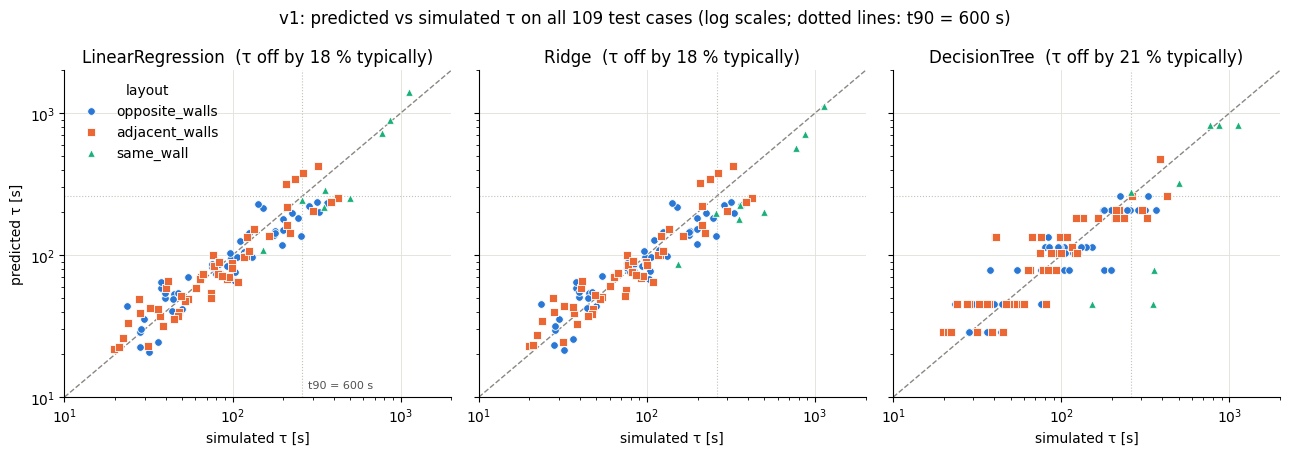

In [12]:
# Colour and marker per layout, the same in every version
LAYOUT_STYLE = {
    "opposite_walls": ("#2a78d6", "o"),
    "adjacent_walls": ("#eb6834", "s"),
    "same_wall": ("#1baf7a", "^"),
}
plot_models = ["LinearRegression", "Ridge", "DecisionTree"]
tau_600 = 600 / LN10  # τ at which t90 = 600 s

low, high = 10, 2000
fig, axes = plt.subplots(1, len(plot_models), figsize=(13, 4.6), sharex=True, sharey=True)
for ax, name in zip(axes, plot_models):
    ax.plot([low, high], [low, high], color="#898781", linewidth=1, linestyle="--", zorder=1)
    ax.axvline(tau_600, color="#c3c2b7", linewidth=0.8, linestyle=":", zorder=1)
    ax.axhline(tau_600, color="#c3c2b7", linewidth=0.8, linestyle=":", zorder=1)
    for layout, (color, marker) in LAYOUT_STYLE.items():
        in_layout = test_df["layout"] == layout
        ax.scatter(
            tau_test[in_layout], tau_pred.loc[in_layout, name],
            s=30, color=color, marker=marker, edgecolor="white", linewidth=0.6,
            label=layout, zorder=2,
        )
    ax.set_title(f"{name}  (τ off by {100 * tau_scores.loc[name, 'median relative error']:.0f} % typically)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(low, high)
    ax.set_ylim(low, high)
    ax.set_xlabel("simulated τ [s]")
    ax.grid(color="#e1e0d9", linewidth=0.6, which="major")
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].text(tau_600 * 1.08, low * 1.15, "t90 = 600 s", color="#52514e", fontsize=8)

axes[0].set_ylabel("predicted τ [s]")
axes[0].legend(title="layout", frameon=False, loc="upper left")
fig.suptitle("v1: predicted vs simulated τ on all 109 test cases (log scales; dotted lines: t90 = 600 s)")
fig.tight_layout()
plt.show()

## 7) What the models learned

The linear model now works on log(τ), so its coefficients act as **factors on τ**: factor = exp(coefficient).

- Numeric inputs are standardised, so their factor applies per standard deviation of the input. A factor of 0.6 for the wind speed means τ drops to 60 % when the wind speed rises by one standard deviation.
- The categories of one input share their effect, so only the ratio between two categories has a meaning. The second table gives these ratios.
- A tilted window always has `hinge = none`, so the effect of tilting is split between the mode and the hinge columns. The table adds both up. It compares windows with the same angle value; a real tilted window (always 6°) also has a smaller angle than a turned one (15–90°), so its τ grows by more.

As in v0, this is not proof of a physical cause.

In [13]:
feature_names = pipelines["LinearRegression"].named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(pipelines["LinearRegression"].named_steps["model"].coef_, index=feature_names)

numeric_factors = np.exp(coefficients[num_cols])
display(pd.DataFrame({
    "standard deviation": X_train[num_cols].std(),
    "factor on τ per standard deviation": numeric_factors,
}).sort_values("factor on τ per standard deviation").round(2))

c = coefficients
ratios = {
    "adjacent_walls instead of opposite_walls": c["layout_adjacent_walls"] - c["layout_opposite_walls"],
    "same_wall instead of opposite_walls": c["layout_same_wall"] - c["layout_opposite_walls"],
}
for w in ("window1", "window2"):
    turned = c[f"{w}_mode_turn"] + (c[f"{w}_hinge_left"] + c[f"{w}_hinge_right"]) / 2
    tilted = c[f"{w}_mode_tilt"] + c[f"{w}_hinge_none"]
    ratios[f"{w} tilted instead of turned"] = tilted - turned
    ratios[f"{w} hinge right instead of left"] = c[f"{w}_hinge_right"] - c[f"{w}_hinge_left"]
display(np.exp(pd.Series(ratios)).round(2).to_frame("factor on τ"))

importances = pd.Series(pipelines["DecisionTree"].named_steps["model"].feature_importances_, index=feature_names)
display(importances.sort_values(ascending=False).head(8).round(3).to_frame("DecisionTree importance"))

,standard deviation,factor on τ per standard deviation
wind_speed_ms,1.14,0.67
window1_angle_deg,28.20,0.84
window2_angle_deg,28.37,0.88
window2_x_m,0.97,1.00
window1_x_m,1.03,1.07


,factor on τ
adjacent_walls instead of opposite_walls,0.95
same_wall instead of opposite_walls,3.76
window1 tilted instead of turned,1.84
window1 hinge right instead of left,1.07
window2 tilted instead of turned,1.96
window2 hinge right instead of left,0.89


,DecisionTree importance
window2_angle_deg,0.354
window1_mode_tilt,0.284
wind_speed_ms,0.248
layout_same_wall,0.094
window1_angle_deg,0.012
window2_x_m,0.008
window1_x_m,0.000
window1_hinge_right,0.000


## 8) Save the results

As in v0: `results/v1_tau.csv` holds the t90 scores on the same 93 test cases, `results/v1_tau_test_predictions.csv` the predicted t90 and τ of every model for all 109 test cases.

In [14]:
summary = results.drop(columns="lowest prediction [s]").reset_index(names="model")
summary.insert(0, "version", VERSION)
summary["target"] = "log(tau_s)"
summary["n_train"] = len(X_train)
summary["n_test"] = len(y_test_t90)
summary.to_csv(RESULTS_DIR / f"{VERSION}.csv", index=False, float_format="%.3f")

test_predictions = pd.concat([
    test_df[[TARGET_COL, TAU_COL]].add_suffix(" simulated"),
    t90_pred.add_prefix("t90 "),
    tau_pred.add_prefix("tau "),
], axis=1)
test_predictions.to_csv(RESULTS_DIR / f"{VERSION}_test_predictions.csv", index_label="case_id", float_format="%.1f")
display(summary.round(3))

,version,model,MAE [s],RMSE [s],R²,target,n_train,n_test
0,v1_tau,Mean value (reference),115.568,142.251,-0.007,log(tau_s),432,93
1,v1_tau,LinearRegression,50.206,75.951,0.713,log(tau_s),432,93
2,v1_tau,Ridge,50.135,77.116,0.704,log(tau_s),432,93
3,v1_tau,DecisionTree,57.922,85.315,0.638,log(tau_s),432,93


## 9) Findings and next version

**Result** (same split as v0): on the 93 test cases with t90, v1 is **not clearly better than v0**. The linear models improve the MAE (53 → 50 s) but lose in RMSE (70 → 76 s) and R² (0.75 → 0.71). The decision tree gets worse (MAE 42 → 58 s, R² 0.81 → 0.64).

**Why** (section 6.2):

- For fast cases (t90 below 200 s, half of the test cases), the error of the linear models roughly halves (56 → 25 s and 35 → 20 s), and there are no negative times any more.
- For slow cases (t90 above 300 s), the error grows. A model fitted on log(τ) treats errors as relative: the typical error of 18 % is a few seconds for a fast case but more than a minute for a slow one. RMSE and R² are dominated by these large absolute errors.
- The tree still has depth 4, i.e. at most 16 different outputs, but now has to cover τ from 16 to 1171 s, so its steps are coarser. Its parameters were chosen for v0.
- The conversion t90 = ln(10) · τ is not the problem: with the simulated τ it misses t90 by only 5 s on average.

**What v1 adds:**

- Every case counts. τ is predicted with a typical error of 18 % on all 109 test cases (linear models), same-wall cases included (22 %).
- The model can say "t90 > 600 s": the linear models recognise 6 of the 16 such test cases and the tree 9, with 1–2 false alarms among the 93 others.
- The linear model's factors are physically plausible (section 7): more wind shortens τ (× 0.67 per 1.1 m/s), both windows in the same wall make it about 3.8 times longer, a tilted window about twice as long, and opposite and adjacent walls hardly differ.

**Which version is better depends on the use:** for t90 in seconds, among setups that reach 90 % within 10 minutes, v0's tree is still the most accurate. For a surrogate that covers every setup, including same-wall and slow cases, and never gives impossible values, v1 is the better base.

**Options for the next version (v2):**

1. Use log(wind speed) as input instead of the wind speed. τ scales with about 1 / wind speed (v0, section 9), which is a straight line in log space.
2. Choose the model complexity (tree depth, Ridge `alpha`) with cross-validation on the training cases instead of keeping the template values.
3. Try stronger non-linear models on log(τ), e.g. a random forest or gradient boosting. They can also learn that the wind acts differently for same-wall windows.